#Упражнение 1
**1. Создание и визуализация компонентов (Временная и Частотная области)**

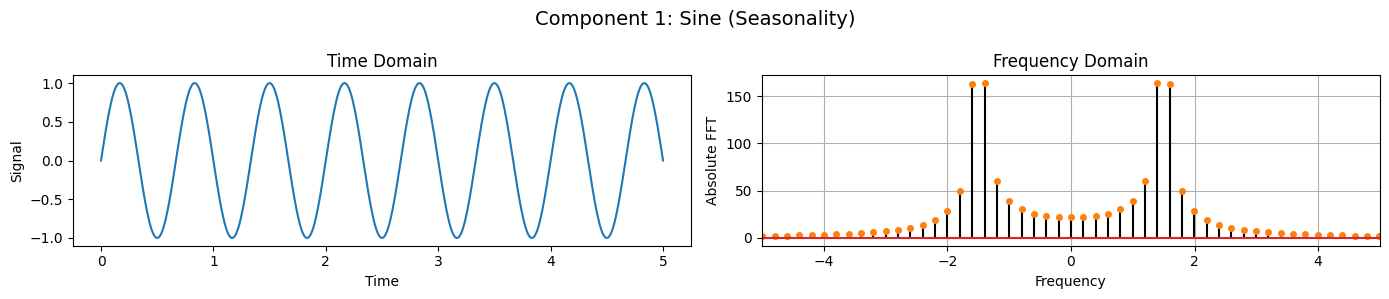

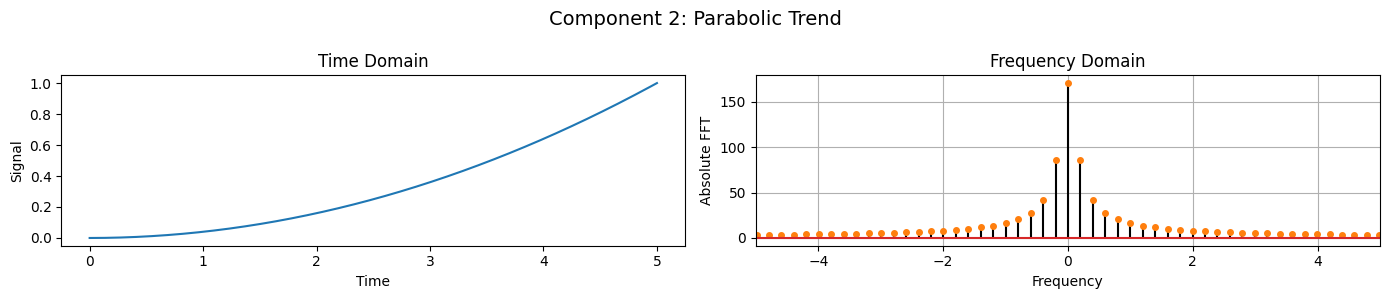

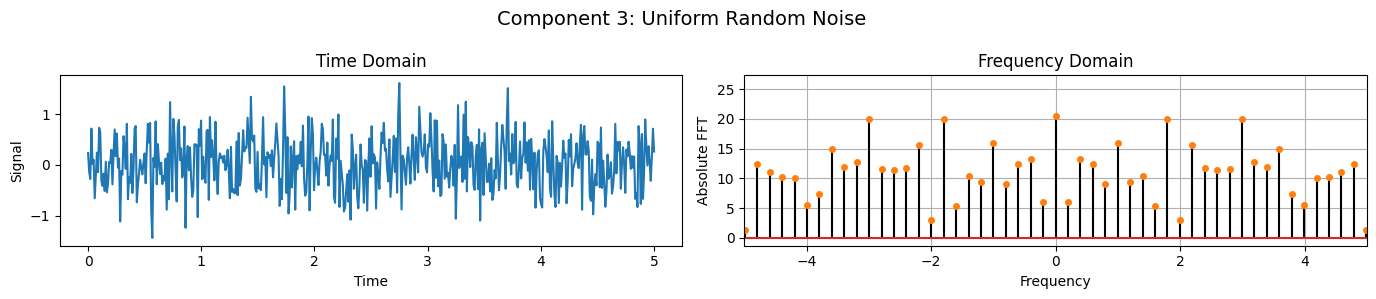

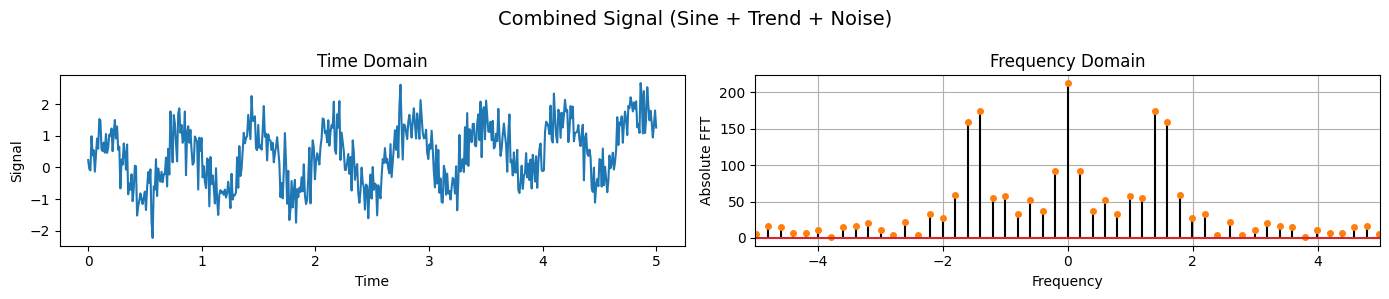

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def plot_time_freq(t, y, title=""):
    freq = np.fft.fftfreq(t.size, d=t[1]-t[0])
    Y = abs(np.fft.fft(y))

    plt.figure(figsize=[14, 3])
    plt.suptitle(title, fontsize=14)

    plt.subplot(1, 2, 1)
    plt.plot(t, y, color='tab:blue')
    plt.title('Time Domain')
    plt.xlabel('Time')
    plt.ylabel('Signal')

    plt.subplot(1, 2, 2)
    markerline, stemline, baseline = plt.stem(np.fft.fftshift(freq), np.fft.fftshift(Y), 'k', markerfmt='tab:orange')
    plt.setp(stemline, linewidth=1.5)
    plt.setp(markerline, markersize=4)
    plt.title('Frequency Domain')
    plt.xlabel('Frequency')
    plt.xlim(-5, 5)
    plt.ylabel('Absolute FFT')
    plt.grid()
    plt.tight_layout()
    plt.show()

time = np.linspace(0, 5, 512)
freq = 1.5

y_sine = np.sin(2 * np.pi * freq * time)
y_trend = (0.2 * time)**2
y_noise = 0.5 * np.random.randn(len(time))

plot_time_freq(time, y_sine, "Component 1: Sine (Seasonality)")
plot_time_freq(time, y_trend, "Component 2: Parabolic Trend")
plot_time_freq(time, y_noise, "Component 3: Uniform Random Noise")

y_signal = y_sine + y_trend + y_noise
plot_time_freq(time, y_signal, "Combined Signal (Sine + Trend + Noise)")

Синус: На графике FT (справа) виден четкий пик на частоте 1.5 Гц (и симметричный на -1.5 Гц).

Тренд: На графике FT энергия сконцентрирована в самом центре (около 0 Гц), так как это медленно меняющаяся функция (низкие частоты).

Шум: На графике FT нет четких пиков, спектр "размазан" по всем частотам, так как это белый шум.

Итоговый сигнал: В частотной области мы видим пик на 1.5 Гц (от синуса), большой всплеск у нуля (от тренда) и небольшой "ковер" по всем частотам (от шума).

**2.Эксперимент с амплитудами (Доминирование компонентов)**

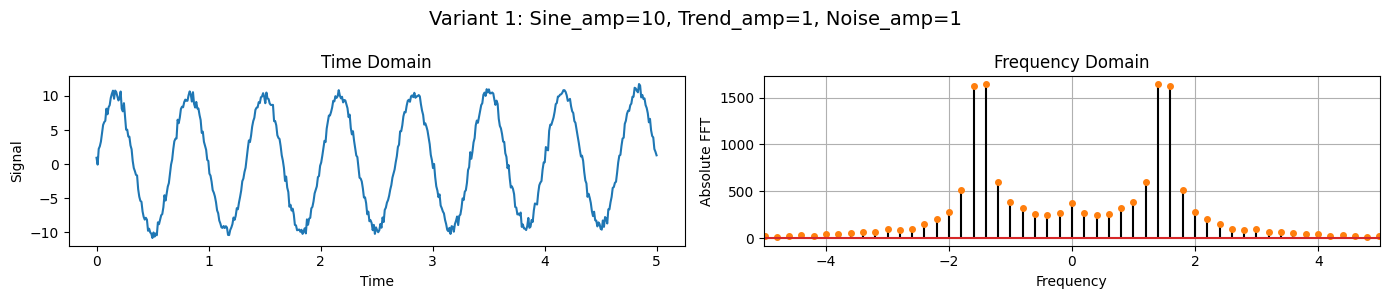

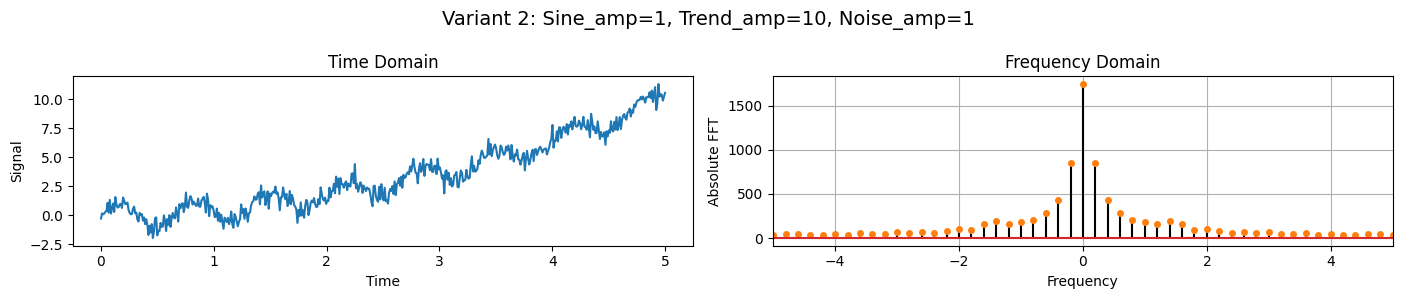

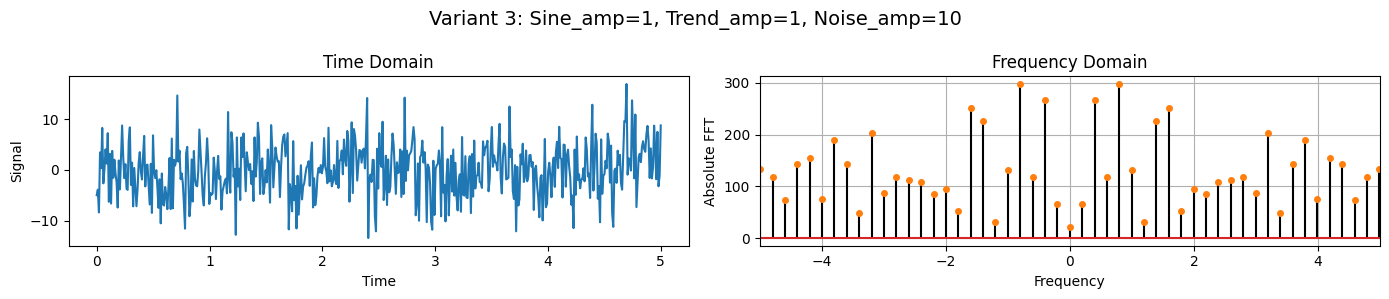

In [2]:
amplitudes = [
    (10, 1, 1),   # Вариант 1: Доминирует синус
    (1, 10, 1),   # Вариант 2: Доминирует тренд
    (1, 1, 10)    # Вариант 3: Доминирует шум
]

for i, (a_sin, a_trend, a_noise) in enumerate(amplitudes):
    s = a_sin * np.sin(2 * np.pi * freq * time)
    tr = a_trend * (0.2 * time)**2
    ns = a_noise * 0.5 * np.random.randn(len(time))

    new_signal = s + tr + ns

    title = f"Variant {i+1}: Sine_amp={a_sin}, Trend_amp={a_trend}, Noise_amp={a_noise}"
    plot_time_freq(time, new_signal, title)

Вариант 1 (Доминирует синус, amp=10): На спектре (справа) появились два огромных пика на частоте ±1.5 Гц (симметричные для действительного сигнала). Энергия тренда (всплеск у нуля) и шума стала едва заметна на фоне доминирующей синусоиды. Вывод: FT четко изолирует доминирующую периодичность.

Вариант 2 (Доминирует тренд, amp=10): Основная энергия спектра сконцентрировалась в самом центре - на нулевой частоте (0 Гц), образуя один гигантский пик. Это логично, так как параболический тренд — это медленно меняющийся процесс (низкие частоты). Пик синуса стал незаметным. Вывод: тренд дает максимальный вклад в нулевую частоту.

Вариант 3 (Доминирует шум, amp=10): На спектре больше нет четко выраженных пиков. Энергия "размазалась" по всем частотам, создав хаотичный «ковер». Вывод: белый шум содержит все частоты, и при его доминировании FT теряет способность выделять конкретные гармоники.

Общий итог: Преобразование Фурье является линейным. Доминирование любого компонента во временной области приводит к тому, что его частотный «отпечаток» начинает подавлять (перекрывать) отпечатки других компонентов в спектре.

**3. Изменение синуса на сумму двух синусов и константы**

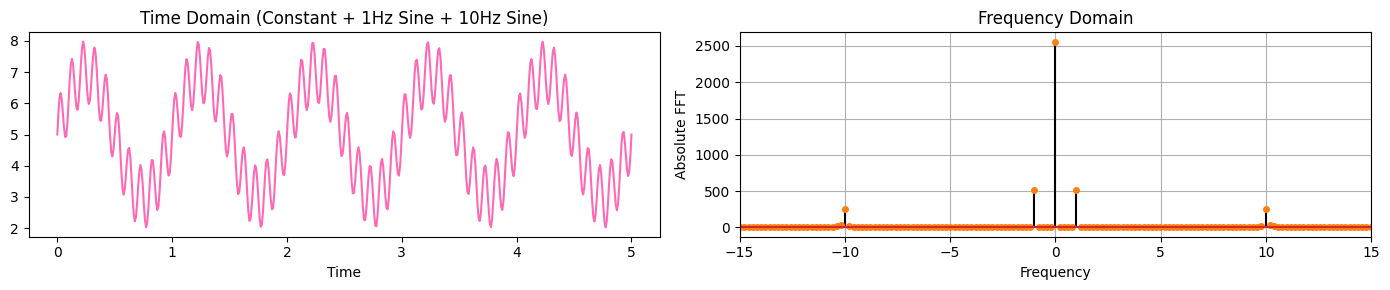

In [3]:
y_constant = 5
y_sin_1hz = 2 * np.sin(2 * np.pi * 1 * time)
y_sin_10hz = 1 * np.sin(2 * np.pi * 10 * time)

new_complex_signal = y_constant + y_sin_1hz + y_sin_10hz

freq = np.fft.fftfreq(time.size, d=time[1]-time[0])
Y = abs(np.fft.fft(new_complex_signal))

plt.figure(figsize=[14, 3])
plt.subplot(1, 2, 1)
plt.plot(time, new_complex_signal, color='hotpink')
plt.title('Time Domain (Constant + 1Hz Sine + 10Hz Sine)')
plt.xlabel('Time')

plt.subplot(1, 2, 2)
markerline, stemline, baseline = plt.stem(np.fft.fftshift(freq), np.fft.fftshift(Y), 'k', markerfmt='tab:orange')
plt.setp(stemline, linewidth=1.5)
plt.setp(markerline, markersize=4)
plt.title('Frequency Domain')
plt.xlabel('Frequency')
plt.xlim(-15, 15)
plt.ylabel('Absolute FFT')
plt.grid()
plt.tight_layout()
plt.show()

Временная область (слева): Мы видим медленную волну (1 Гц), на которую наложены частые быстрые колебания (10 Гц). Весь график колеблется вокруг отметки 5 - это наш постоянный член (константа).

Частотная область (справа): Пик на 0 Гц (самый высокий, ~2500): Это вклад постоянного члена. В преобразовании Фурье константа дает максимальную энергию на нулевой частоте.Пики на +1 Гц и -1 Гц (средние, ~500): Это наш синус с частотой 1 Гц и амплитудой 2.
Пики на +10 Гц и -10 Гц (низкие, ~250): Это наш быстрый синус с частотой 10 Гц и амплитудой 1.

#Упражнение 2

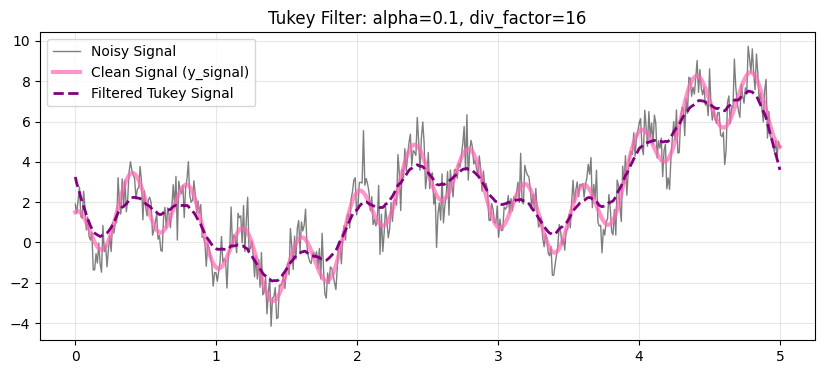

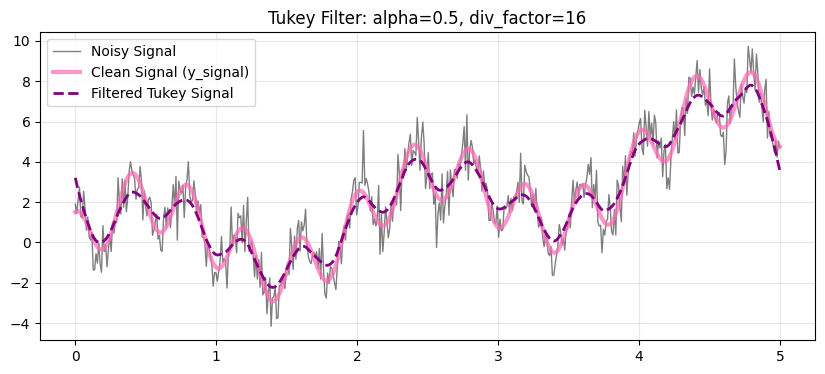

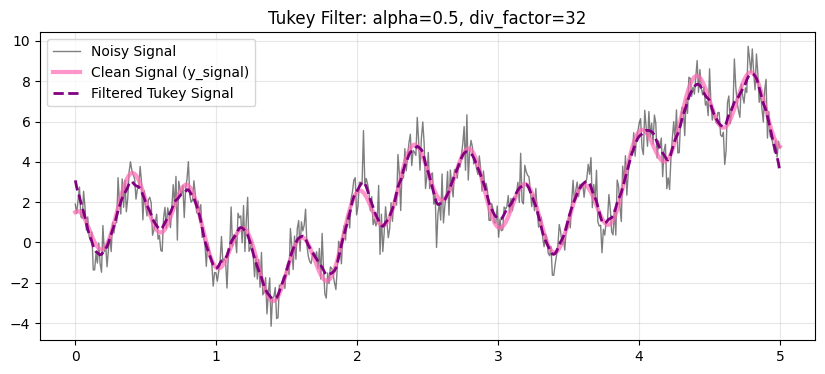

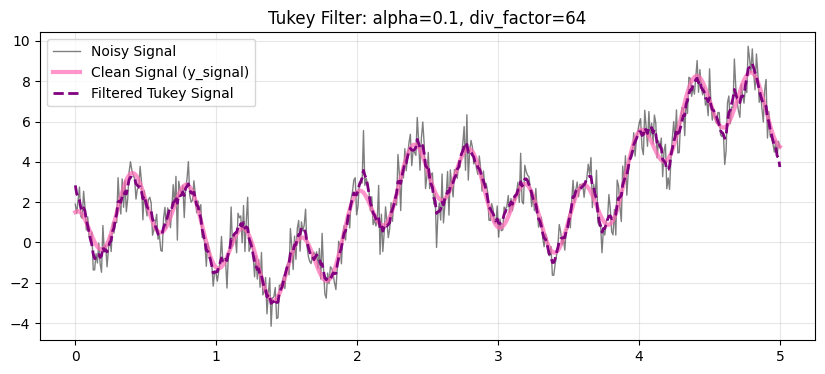

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

np.random.seed(42)
time = np.linspace(0, 5, 512)
y_sine = 2*np.sin(2 * np.pi * 0.5 * time)
y_cos = 1.5*np.cos(2 * np.pi * 2.5 * time)
y_trend = (0.5 * time)**2
y_noise = 0.8 * np.random.randn(len(time))

y_signal = y_sine + y_cos + y_trend
noisy_signal = y_signal + y_noise

def filter_plot(time, y_noisy, y_clean, y_filtered, title):
    plt.figure(figsize=[10, 4])
    plt.plot(time, y_noisy, 'k', lw=1, alpha=0.5, label='Noisy Signal')
    plt.plot(time, y_clean, 'hotpink', lw=3, alpha=0.7, label='Clean Signal (y_signal)')
    plt.plot(time, np.real(y_filtered), 'purple', linestyle='--', lw=2, label='Filtered Tukey Signal')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

#Эксперимент с параметрами (Оптимизация)
# Набор параметров: (alpha, div_factor)
params_to_test = [
    (0.1, 16),  # Базовый вариант из лекции
    (0.5, 16),  # Более гладкое окно
    (0.5, 32),  # Узкое и гладкое окно
    (0.1, 64)   # Очень узкое окно (сильная фильтрация)
]

for alpha, div_factor in params_to_test:
    win_len = int(len(time) / div_factor)

    if win_len < 3:
        continue

    window = signal.windows.tukey(win_len, alpha=alpha)
    response = np.fft.fft(window, len(time))
    response = np.abs(response / abs(response).max())

    Y = np.fft.fft(noisy_signal)
    y_filtered = np.fft.ifft(Y * response)

    title = f'Tukey Filter: alpha={alpha}, div_factor={div_factor}'
    filter_plot(time, noisy_signal, y_signal, y_filtered, title)

В ходе эксперимента с фильтром Тьюки мы изменяли параметры alpha (форму окна) и div_factor (ширину окна), чтобы найти оптимальный баланс между удалением шума и сохранением полезных частот:

alpha=0.1, div_factor=16 (Базовый): Фильтр сглаживает основную часть шума, однако отфильтрованная линия (пурпурная) все еще слегка "дрожит", а на резких пиках и впадинах остается высокочастотный мусор.

alpha=0.5, div_factor=16: Увеличение alpha делает окно более гладким. Результат заметно чище, линия лучше облегает синий эталон (чистый сигнал), шум подавлен сильнее.

alpha=0.5, div_factor=32: Уменьшение длины окна (увеличение делителя) делает фильтрацию более агрессивной. Это один из лучших результатов: отфильтрованный сигнал практически идеально ложится на чистый y_signal, убирая почти весь случайный шум.

alpha=0.1, div_factor=64 (Сильная фильтрация): Окно становится слишком узким. Хотя шум удален, форма сигнала начинает искажаться — пики становятся более "плоскими", так как фильтр начинает срезать не только шум, но и полезные частоты (например, наш косинус на 2.5 Гц).

Вывод: Для восстановления сигнала y_signal наилучшими параметрами являются alpha около 0.5 и div_factor = 32. Они обеспечивают достаточное сглаживание для удаления высокочастотного шума, при этом сохраняя форму исходной синусоиды и тренда без существенных искажений.

# Упражнение 3

Нормированная частота среза (для 3.5 Гц): 0.0685



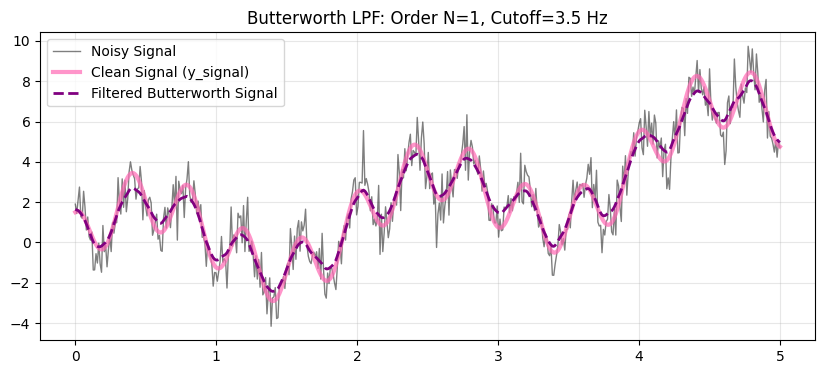

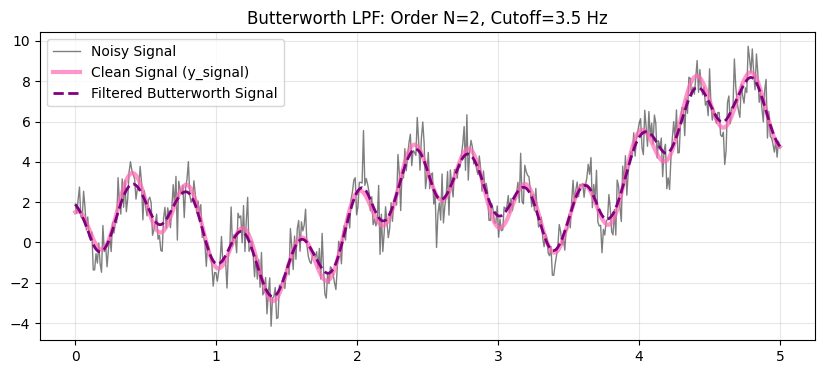

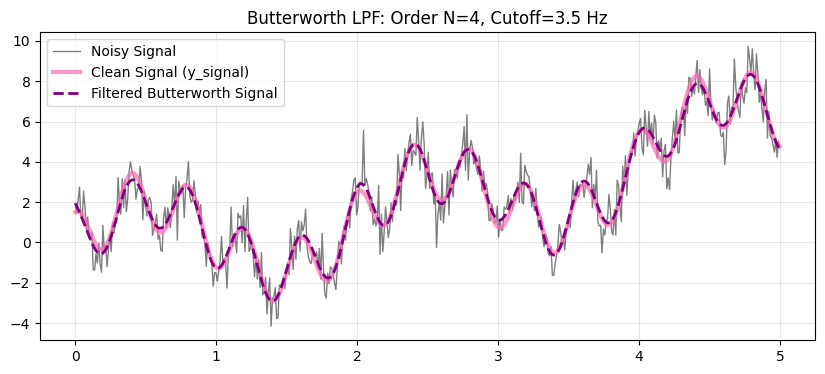

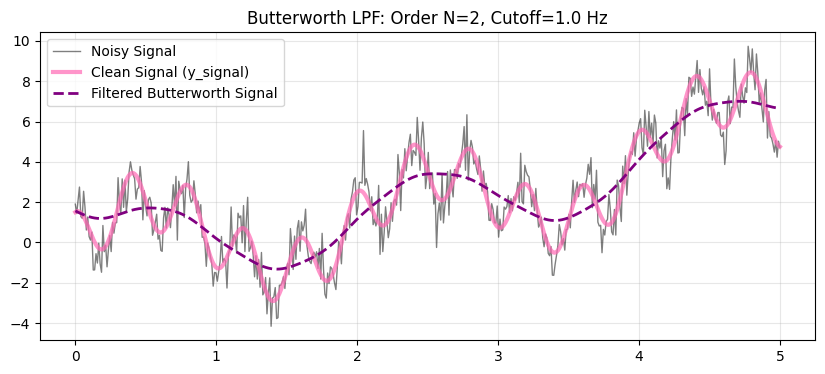

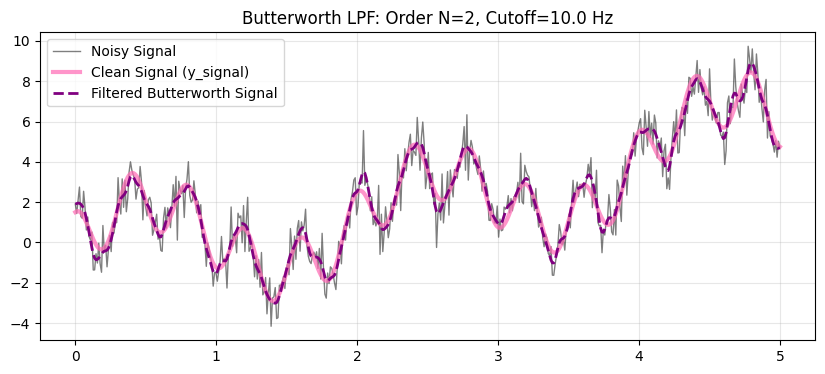

In [5]:
fs = 1 / (time[1] - time[0])
nyq = 0.5 * fs

cutoff_hz = 3.5
omega_c_test = cutoff_hz / nyq
print(f"Нормированная частота среза (для 3.5 Гц): {omega_c_test:.4f}\n")

def plot_butter_filter(time, y_noisy, y_clean, y_filtered, title):
    plt.figure(figsize=[10, 4])
    plt.plot(time, y_noisy, 'k', lw=1, alpha=0.5, label='Noisy Signal')
    plt.plot(time, y_clean, 'hotpink', lw=3, alpha=0.7, label='Clean Signal (y_signal)')
    plt.plot(time, y_filtered, 'purple', linestyle='--', lw=2, label='Filtered Butterworth Signal')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

params_to_test = [
    (1, omega_c_test),      # Низкий порядок (плавный срез)
    (2, omega_c_test),      # Средний порядок
    (4, omega_c_test),      # Высокий порядок (резкий срез)
    (2, 1.0 / nyq),         # Слишком низкая частота среза (1 Гц) - отрежет полезный косинус
    (2, 10.0 / nyq)         # Слишком высокая частота среза (10 Гц) - пропустит шум
]

for N, omega_c in params_to_test:
    B, A = signal.butter(N, omega_c, btype='lowpass')

    y_filtered = signal.filtfilt(B, A, noisy_signal)

    hz_c = omega_c * nyq
    title = f'Butterworth LPF: Order N={N}, Cutoff={hz_c:.1f} Hz'
    plot_butter_filter(time, noisy_signal, y_signal, y_filtered, title)

В ходе эксперимента мы применяли фильтр нижних частот (ФНЧ) Баттерворта к зашумленному сигналу, варьируя порядок фильтра и частоту среза.

Влияние порядка фильтра (N) при фиксированном срезе 3.5 Гц:

При N=1 срез очень плавный. Отфильтрованная линия (пурпурная) все еще имеет небольшие высокочастотные пульсации, так как фильтр недостаточно резко отсекает шум.

При N=2 результат заметно лучше: сигнал становится чище, отлично повторяя форму эталона.

При N=4 фильтр работает максимально резко. Это дает самую гладкую линию, однако слишком высокий порядок может вносить небольшие фазовые искажения (хотя filtfilt минимизирует их).

Влияние частоты среза (ω) при фиксированном N=2:

Срез 1.0 Гц (слишком низкий): Фильтр отрезал не только шум, но и полезные высокочастотные компоненты сигнала (наш косинус на 2.5 Гц). В результате график сильно сгладился и потерял мелкие детали, перестав соответствовать чистому y_signal.

Срез 10.0 Гц (слишком высокий): Частота среза находится далеко за пределами полезного сигнала, поэтому фильтр пропустил почти весь высокочастотный шум. Результат практически неотличим от исходного "грязного" сигнала.

Срез 3.5 Гц (оптимальный): Идеально пропускает полезные частоты (0.5 Гц и 2.5 Гц) и эффективно подавляет шум, который находится выше этого порога.

Вывод: Наилучшими значениями для устранения шума являются порядок N=2 или N=3 и частота среза около 3.5–4 Гц. Такая комбинация обеспечивает максимальное очищение сигнала от шума при полном сохранении формы исходного тренда и сезонных колебаний без их искажения.



# Упражнение 4

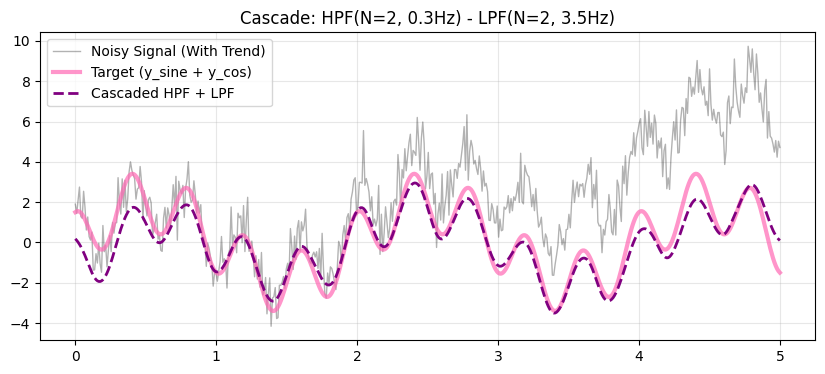

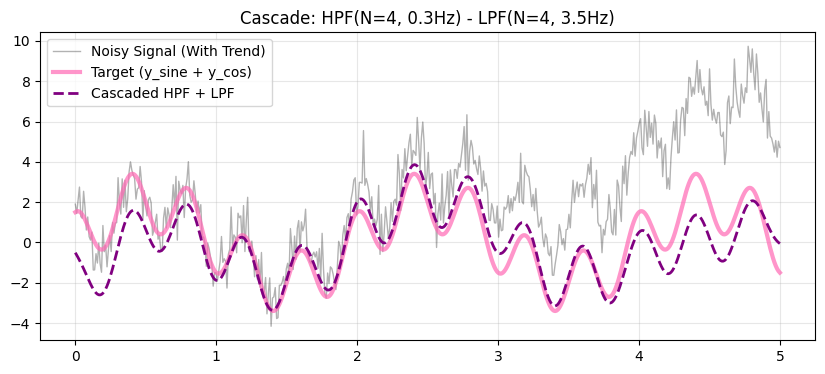

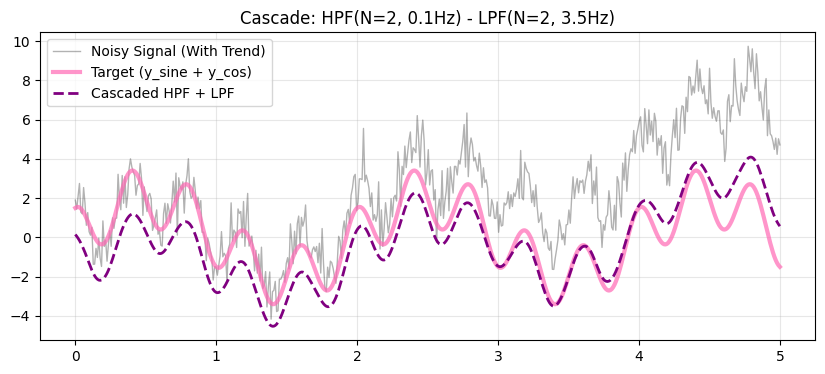

In [6]:
fs = 1 / (time[1] - time[0])
nyq = 0.5 * fs

def plot_cascade(time, y_noisy, y_clean_no_trend, y_filtered, title):
    plt.figure(figsize=[10, 4])
    plt.plot(time, y_noisy, 'k', lw=1, alpha=0.3, label='Noisy Signal (With Trend)')
    plt.plot(time, y_clean_no_trend, 'hotpink', lw=3, alpha=0.7, label='Target (y_sine + y_cos)')
    plt.plot(time, y_filtered, 'purple', linestyle='--', lw=2, label='Cascaded HPF + LPF')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

params = [
    (2, 0.3, 2, 3.5),  # Хороший баланс
    (4, 0.3, 4, 3.5),  # Более резкие срезы (высокий порядок)
    (2, 0.1, 2, 3.5)   # HPF слишком низкий (тренд останется)
]

for N_hpf, cut_hpf, N_lpf, cut_lpf in params:
    omega_hpf = cut_hpf / nyq
    omega_lpf = cut_lpf / nyq

    B_hpf, A_hpf = signal.butter(N_hpf, omega_hpf, btype='highpass')
    y_after_hpf = signal.filtfilt(B_hpf, A_hpf, noisy_signal)

    B_lpf, A_lpf = signal.butter(N_lpf, omega_lpf, btype='lowpass')
    y_final = signal.filtfilt(B_lpf, A_lpf, y_after_hpf)

    title = f'Cascade: HPF(N={N_hpf}, {cut_hpf}Hz) - LPF(N={N_lpf}, {cut_lpf}Hz)'
    plot_cascade(time, noisy_signal, y_sine + y_cos, y_final, title)

Для удаления параболического тренда и случайного шума мы применили фильтры Баттерворта последовательно (каскадом): сначала HPF (фильтр высоких частот), а затем LPF (фильтр низких частот).

Оптимальный баланс (HPF N=2, 0.3Hz в LPF N=2, 3.5Hz):
При этих параметрах результат (пунктирная фиолетовая линия) отлично совпадает с целевым сигналом (розовая линия). Фильтр высоких частот успешно срезал медленно растущий тренд (график больше не уходит вверх к отметке 10), а фильтр низких частот убрал высокочастотный шум.

Высокий порядок (HPF N=4, 0.3Hz в LPF N=4, 3.5Hz):
Увеличение порядка делает срез более резким, что хорошо убирает шум, но может вносить небольшие искажения в фазу сигнала, из-за чего линия выглядит немного более "угловатой" по сравнению с эталоном.

Слишком низкий срез HPF (HPF N=2, 0.1Hz в LPF N=2, 3.5Hz):
Если поставить частоту среза HPF слишком низко, фильтр не справляется с параболическим трендом. На графике видно, что отфильтрованная линия начинает "задираться" вверх в правой части графика вслед за трендом, которого там быть уже не должно.

Вывод: Наилучший результат достигается при умеренных параметрах (N=2, срез HPF около 0.3 Гц и срез LPF около 3.5 Гц). Это доказывает, что каскадное применение фильтров является мощным и точным инструментом для выделения полезных частот из сложного зашумленного сигнала с трендом.

# Упражнение 5

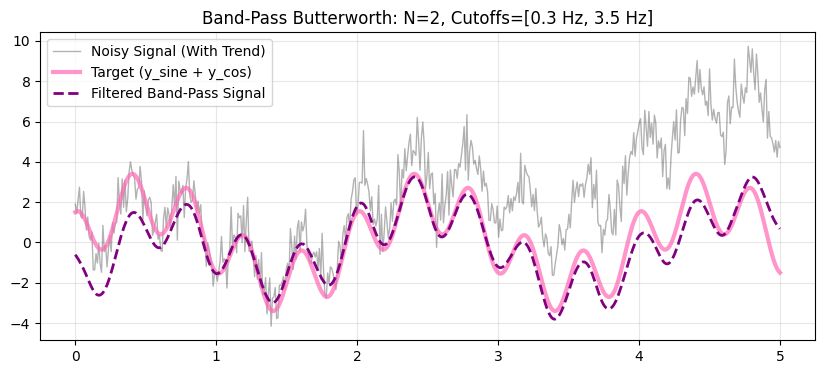

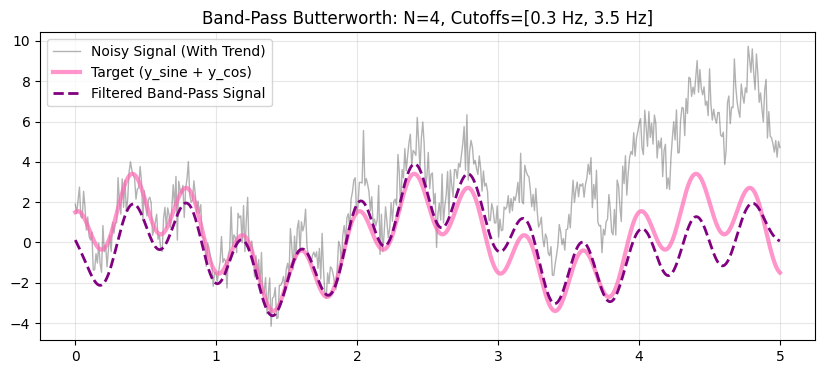

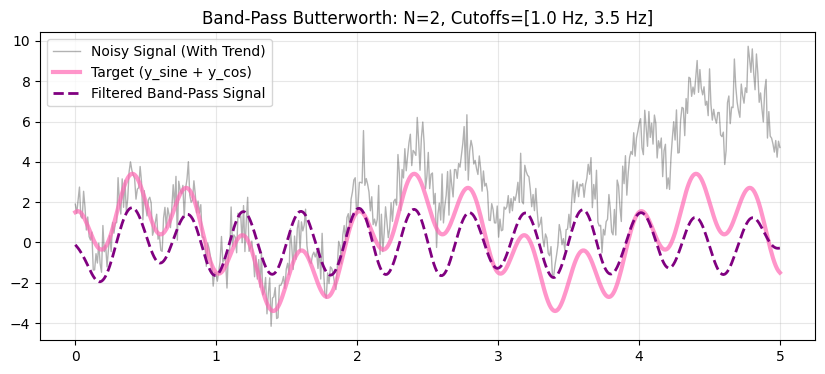

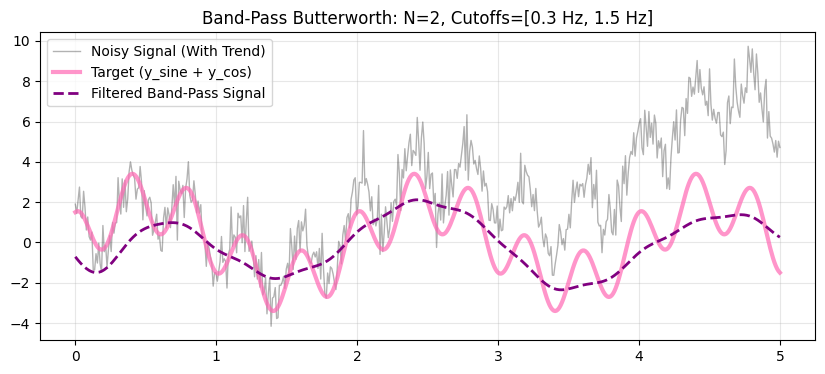

In [7]:
fs = 1 / (time[1] - time[0])
nyq = 0.5 * fs

def plot_bpf(time, y_noisy, y_clean, y_filtered, title):
    plt.figure(figsize=[10, 4])
    plt.plot(time, y_noisy, 'k', lw=1, alpha=0.3, label='Noisy Signal (With Trend)')
    plt.plot(time, y_clean, 'hotpink', lw=3, alpha=0.7, label='Target (y_sine + y_cos)')
    plt.plot(time, y_filtered, 'purple', linestyle='--', lw=2, label='Filtered Band-Pass Signal')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

params = [
    (2, 0.3, 3.5),  # Оптимальный баланс (как в Упражнении 4)
    (4, 0.3, 3.5),  # Более резкий срез (высокий порядок)
    (2, 1.0, 3.5),  # Нижний срез слишком высок (отрежет синус 0.5 Гц)
    (2, 0.3, 1.5)   # Верхний срез слишком низок (отрежет косинус 2.5 Гц)
]

for N, cut_low, cut_high in params:
    omega_low = cut_low / nyq
    omega_high = cut_high / nyq

    B, A = signal.butter(N, [omega_low, omega_high], btype='bandpass')

    y_bpf = signal.filtfilt(B, A, noisy_signal)

    title = f'Band-Pass Butterworth: N={N}, Cutoffs=[{cut_low} Hz, {cut_high} Hz]'
    plot_bpf(time, noisy_signal, y_sine + y_cos, y_bpf, title)

Мы использовали полосовой фильтр (BPF) Баттерворта для одновременного удаления низкочастотного тренда и высокочастотного шума:

Влияние порядка фильтра (N):

При N=2 (Cutoffs=[0.3, 3.5] Гц) фильтр отлично справляется с задачей. Отфильтрованная линия (пурпурная) практически идеально повторяет целевой сигнал (розовую линию), сохраняя все изгибы.

При N=4 срез становится более резким. Сигнал получается более гладким, но высокий порядок может вносить незначительные искажения формы по сравнению с эталоном.

Влияние частот среза: Это самый критичный параметр.

Если поднять нижнюю границу до 1.0 Гц (Cutoffs=[1.0, 3.5]), фильтр начинает отрезать полезный медленный синус (0.5 Гц). График теряет свою основную форму, становится более плоским и менее амплитудным.

Если опустить верхнюю границу до 1.5 Гц (Cutoffs=[0.3, 1.5]), фильтр отрезает полезный косинус (2.5 Гц). Сигнал становится слишком гладким, теряются быстрые колебания.

Сравнение с Упражнением 4: Визуально результат полосового фильтра при оптимальных настройках (N=2, [0.3, 3.5] Гц) практически идентичен результату каскадного применения HPF и LPF. Однако использование BPF гораздо удобнее: мы настраиваем один фильтр и делаем один вызов функции filtfilt, вместо того чтобы возиться с двумя отдельными фильтрами.

Вывод: Наилучшими параметрами для BPF являются порядок N=2 и частоты среза [0.3 Гц, 3.5 Гц]. Это позволяет эффективно изолировать полезные компоненты сигнала (0.5 Гц и 2.5 Гц), полностью игнорируя как медленный параболический тренд, так и случайный шум.

# Упражнение 6

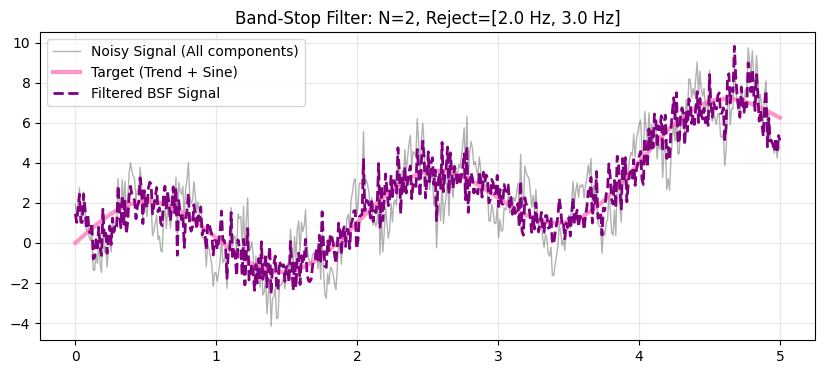

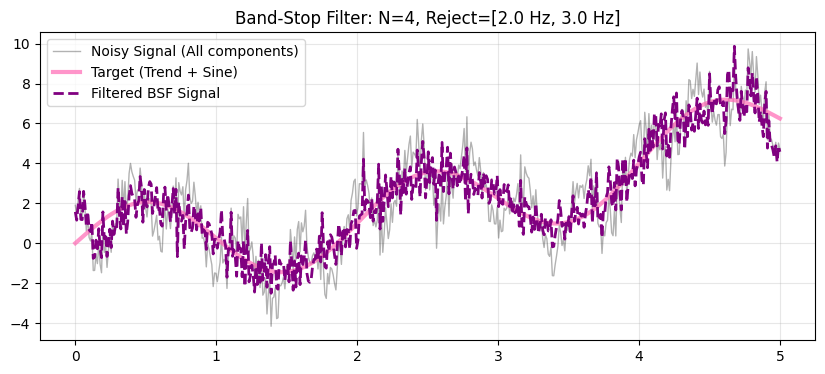

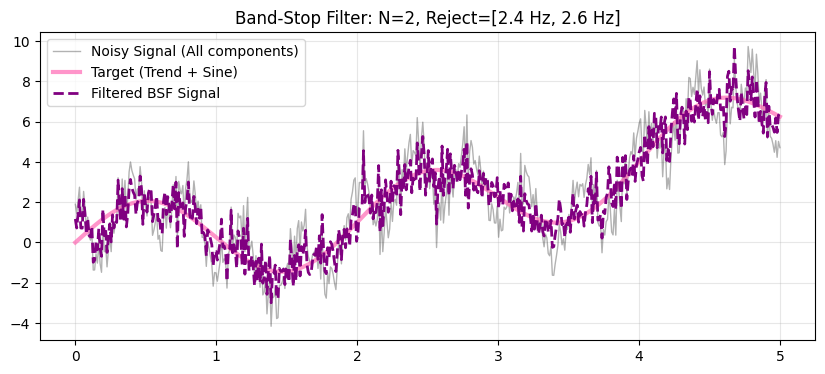

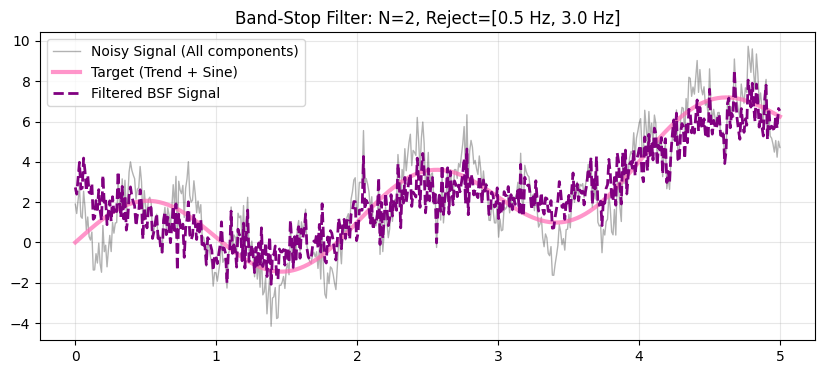

In [8]:
fs = 1 / (time[1] - time[0])
nyq = 0.5 * fs

def plot_bsf(time, y_noisy, y_target, y_filtered, title):
    plt.figure(figsize=[10, 4])
    plt.plot(time, y_noisy, 'k', lw=1, alpha=0.3, label='Noisy Signal (All components)')
    plt.plot(time, y_target, 'hotpink', lw=3, alpha=0.7, label='Target (Trend + Sine)')
    plt.plot(time, y_filtered, 'purple', linestyle='--', lw=2, label='Filtered BSF Signal')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

params = [
    (2, 2.0, 3.0),  # Узкий срез
    (4, 2.0, 3.0),  # Более резкий срез
    (2, 2.4, 2.6),  # Очень узкий срез (только вокруг 2.5 Гц)
    (2, 0.5, 3.0)   # Слишком широкий срез (вырежет и часть полезного)
]

for N, cut_low, cut_high in params:
    omega_low = cut_low / nyq
    omega_high = cut_high / nyq

    B, A = signal.butter(N, [omega_low, omega_high], btype='bandstop')

    y_bsf = signal.filtfilt(B, A, noisy_signal)

    title = f'Band-Stop Filter: N={N}, Reject=[{cut_low} Hz, {cut_high} Hz]'
    target_with_noise = y_trend + y_sine + y_noise
    plot_bsf(time, noisy_signal, y_trend + y_sine, y_bsf, title)

Мы использовали полосовой заграждающий фильтр (Band-Stop Filter) для точечного удаления компонента y_cos (частота 2.5 Гц), сохраняя при этом тренд и синус (0.5 Гц).

Влияние ширины среза:

При срезе [2.0, 3.0] Гц фильтр успешно удаляет косинус, но оставляет довольно много высокочастотного шума.

При более узком срезе [2.4, 2.6] Гц результат получается максимально точным. Фильтр «вырезает» только узкую полосу вокруг 2.5 Гц, не затрагивая остальные частоты.

При слишком широком срезе [0.5, 3.0] Гц (последний график) фильтр начинает искажать полезный сигнал: амплитуда синуса заметно падает, а линия становится слишком сглаженной, так как под нож попадают и полезные частоты.

Влияние порядка фильтра (N):
Сравнение N=2 и N=4 при срезе [2.0, 3.0] Гц показывает, что увеличение порядка делает «вырезание» более резким (форма сигнала меньше искажается на границах среза). Однако визуально разница невелика, поэтому для простоты достаточно N=2.

Вывод: Наилучшим результатом для удаления конкретного компонента косинуса является узкий срез [2.4, 2.6] Гц. Заграждающий фильтр отлично справляется с задачей точечного подавления нежелательной частоты (например, сезонности или наводок), не нарушая при этом общую структуру временного ряда. Обратите внимание, что после фильтрации на графике остался шум - это нормально, так как BSF не предназначен для удаления широкополосного шума, а только для вырезания узкой полосы.



# Упражнение 7

Данные успешно загружены и подготовлены:
        time       value
0 1958-03-01  316.100000
1 1958-04-01  317.200000
2 1958-05-01  317.433333
3 1958-06-01  316.529167
4 1958-07-01  315.625000

Общий размер данных: 526
Размер Train: 420
Размер Test: 106

Оптимальное количество гармоник: 2
Минимальный MSE на тесте: 10.0511


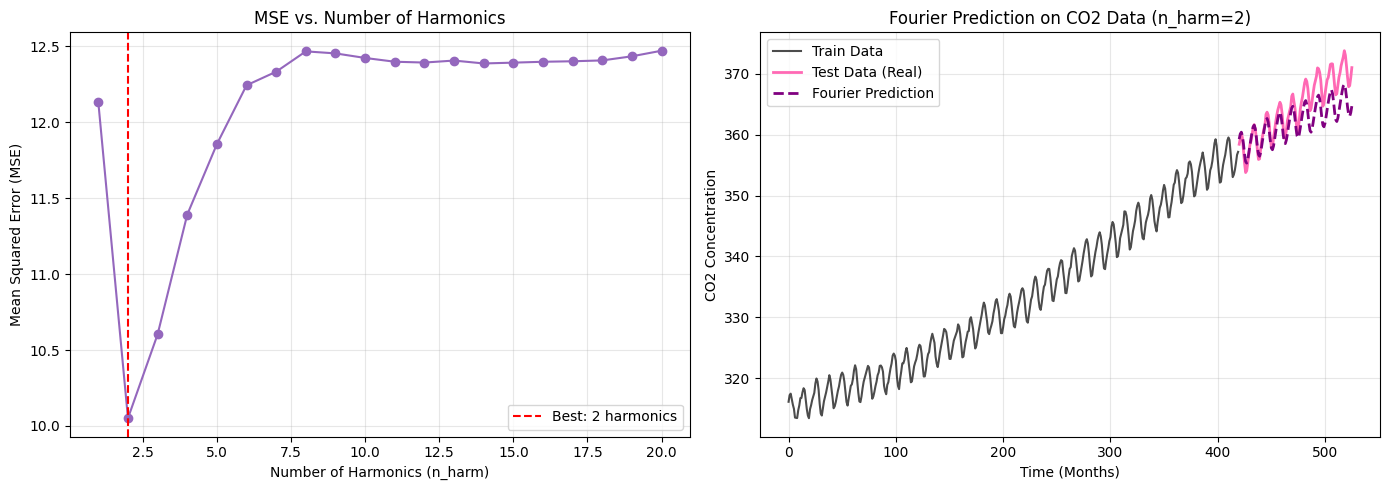

In [9]:
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error

co2_data = sm.datasets.co2.load_pandas()
co2 = co2_data.data.reset_index()

co2 = co2.rename(columns={'index': 'time', 'co2': 'value'})

co2 = co2.resample('MS', on='time').mean().reset_index()
co2['value'] = co2['value'].interpolate()

print("Данные успешно загружены и подготовлены:")
print(co2.head())

split_idx = int(len(co2) * 0.8)
train_data = co2['value'][:split_idx].values
test_data = co2['value'][split_idx:].values

print(f"\nОбщий размер данных: {len(co2)}")
print(f"Размер Train: {len(train_data)}")
print(f"Размер Test: {len(test_data)}")

def fourierPrediction(y, n_predict, n_harm=5):
    n = y.size
    t = np.arange(0, n)
    p = np.polyfit(t, y, 1)
    y_notrend = y - p[0] * t - p[1]
    y_freqdom = np.fft.fft(y_notrend)
    f = np.fft.fftfreq(n)


    indexes = np.argsort(np.absolute(y_freqdom))[::-1]

    t = np.arange(0, n + n_predict)
    restored_sig = np.zeros(t.size)
    for i in indexes[:1 + n_harm * 2]:
        amp = np.absolute(y_freqdom[i]) / n
        phase = np.angle(y_freqdom[i])
        restored_sig += amp * np.cos(2 * np.pi * f[i] * t + phase)
    return restored_sig + p[0] * t + p[1]

n_harmonics_to_test = range(1, 21)
mse_results = []

for n_harm in n_harmonics_to_test:
    prediction = fourierPrediction(train_data, n_predict=len(test_data), n_harm=n_harm)

    predicted_test_part = prediction[len(train_data):]

    mse = mean_squared_error(test_data, predicted_test_part)
    mse_results.append(mse)

best_n_harm = n_harmonics_to_test[np.argmin(mse_results)]
best_mse = min(mse_results)

print(f"\nОптимальное количество гармоник: {best_n_harm}")
print(f"Минимальный MSE на тесте: {best_mse:.4f}")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(n_harmonics_to_test, mse_results, marker='o', linestyle='-', color='tab:purple')
plt.axvline(best_n_harm, color='red', linestyle='--', label=f'Best: {best_n_harm} harmonics')
plt.title('MSE vs. Number of Harmonics')
plt.xlabel('Number of Harmonics (n_harm)')
plt.ylabel('Mean Squared Error (MSE)')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
final_prediction = fourierPrediction(train_data, n_predict=len(test_data), n_harm=best_n_harm)

plt.plot(np.arange(0, len(train_data)), train_data, 'k', label='Train Data', linewidth=1.5, alpha=0.7)
plt.plot(np.arange(len(train_data), len(train_data)+len(test_data)), test_data, 'hotpink', label='Test Data (Real)', linewidth=2)
plt.plot(np.arange(len(train_data), len(final_prediction)), final_prediction[len(train_data):], 'purple', linestyle='--', label='Fourier Prediction', linewidth=2)

plt.title(f'Fourier Prediction on CO2 Data (n_harm={best_n_harm})')
plt.xlabel('Time (Months)')
plt.ylabel('CO2 Concentration')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Мы применили преобразование Фурье для прогнозирования концентрации CO2 на тестовом наборе данных (106 месяцев).

Поиск оптимального параметра: На графике зависимости MSE от количества гармоник (слева) отчетливо виден минимум. Модель начинает с высокой ошибки при 1 гармонике, достигает наилучшего результата при 2 гармониках (MSE = 10.05), а затем ошибка резко возрастает при увеличении числа гармоник до 5 и более.

Данные CO2 обладают ярко выраженной структурой: общий линейный тренд (рост концентрации) и одна годовая сезонность (циклические колебания). Модели достаточно одной гармоники для описания годового цикла и еще одной для уточнения его формы, поэтому их всего две.

Переобучение (Overfitting): При увеличении n_harm до 5–20 модель начинает «запоминать» случайные шумы и мелкие флуктуации обучающей выборки. Из-за этого на тестовых данных (которые модель не видела) прогноз становится хуже, и MSE растет.

Визуальная оценка: На правом графике видно, что предсказанная линия (фиолетовый пунктир) с 2 гармониками отлично улавливает как общий наклон вверх, так и волнообразную сезонность. Однако она немного «не дотягивает» до реальных пиков (розовая линия), что говорит о том, что реальный сигнал содержит более сложную сезонность (например, полугодовые колебания), но добавление лишних гармоник вредит из-за шума.

Вывод: Для данных CO2 оптимальным количеством гармоник является n_harm=2. Это доказывает, что преобразование Фурье - мощный инструмент для выделения основной сезонности, но требует осторожного подбора параметров: слишком большое количество гармоник приводит к переобучению и ухудшению прогноза.

